# SVM para predição de doença cardíaca

**Como executar:** coloque o arquivo `Heart.csv` na mesma pasta deste notebook e use *Kernel → Restart & Run All*.

Bibliotecas necessárias: `numpy pandas matplotlib scikit-learn` (se faltar alguma: `pip install numpy pandas matplotlib scikit-learn`).

In [1]:
%matplotlib inline
# -*- coding: utf-8 -*-
import itertools, warnings, json
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, confusion_matrix
warnings.filterwarnings("ignore")
SEED = 42
import os; os.makedirs("figs", exist_ok=True); FIG = "figs/"
plt.rcParams.update({"figure.dpi": 130, "font.size": 9})

## Dados

In [2]:
# Dados
df = pd.read_csv("Heart.csv", index_col=0)
n0 = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Linhas originais: {n0} | após remover NA: {len(df)}")
y = (df["AHD"] == "Yes").astype(int)          # 1 = doença cardíaca
X_all = df.drop(columns="AHD")
Xtr_all, Xte_all, ytr, yte = train_test_split(
    X_all, y, test_size=0.30, stratify=y, random_state=SEED)
print("Treino:", len(ytr), "prop. DC = %.3f" % ytr.mean(),
      "| Teste:", len(yte), "prop. DC = %.3f" % yte.mean())

Linhas originais: 303 | após remover NA: 297
Treino: 207 prop. DC = 0.459 | Teste: 90 prop. DC = 0.467


## Seleção de características

In [3]:
# Seleção de características
quant = ["Age", "RestBP", "Chol", "MaxHR", "Oldpeak", "Ca"]  # quantitativas/ordinais
mi = pd.Series(mutual_info_classif(Xtr_all[quant], ytr, random_state=SEED), index=quant)\
       .sort_values(ascending=False)
print("\nInformação mútua (treino):\n", mi.round(3))
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
res = []
for a, b in itertools.combinations(quant, 2):
    pipe = Pipeline([("sc", StandardScaler()), ("svm", SVC(kernel="rbf", C=1, gamma="scale"))])
    s = cross_val_score(pipe, Xtr_all[[a, b]], ytr, cv=cv).mean()
    res.append((a, b, s))
res = pd.DataFrame(res, columns=["f1", "f2", "acc_cv"]).sort_values("acc_cv", ascending=False)
print("\nMelhores pares (CV no treino):\n", res.head(6).round(3))
F = list(mi.index[:2])
print("Características escolhidas:", F)

Xtr, Xte = Xtr_all[F].values, Xte_all[F].values
ytr_, yte_ = ytr.values, yte.values


Informação mútua (treino):
 MaxHR      0.111
Oldpeak    0.108
Ca         0.071
RestBP     0.047
Age        0.022
Chol       0.009
dtype: float64

Melhores pares (CV no treino):
          f1     f2  acc_cv
8    RestBP     Ca   0.720
14  Oldpeak     Ca   0.715
4       Age     Ca   0.715
11     Chol     Ca   0.705
13    MaxHR     Ca   0.705
2       Age  MaxHR   0.705
Características escolhidas: ['MaxHR', 'Oldpeak']


## Gráficos treino e teste

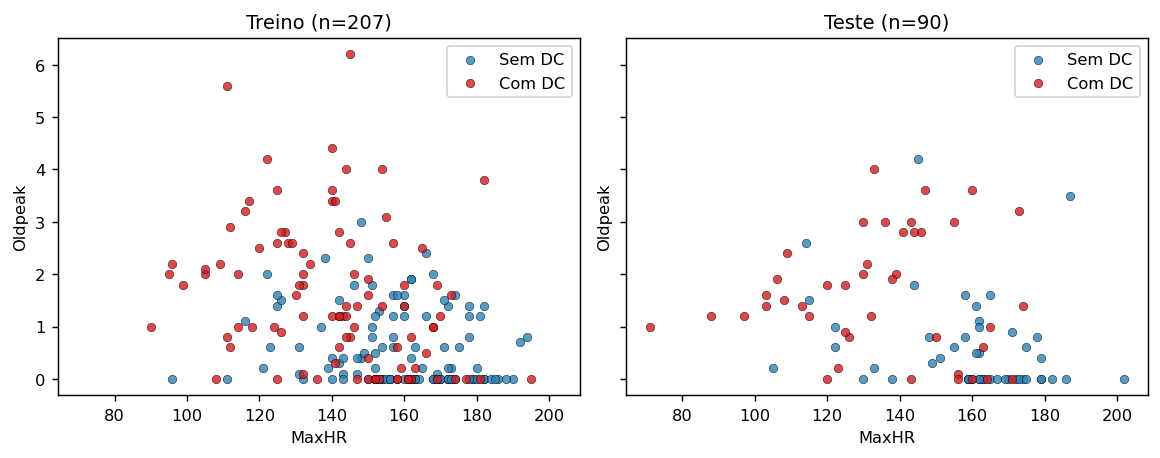

In [4]:
# Gráficos treino e teste
COL = ["#2b83ba", "#d7191c"]; CMAP = ListedColormap(["#a6cee3", "#fb9a99"])
def scatter(ax, X, y, title):
    for c, lab in enumerate(["Sem DC", "Com DC"]):
        ax.scatter(X[y == c, 0], X[y == c, 1], c=COL[c], s=22, edgecolor="k", lw=.3, label=lab, alpha=.8)
    ax.set_xlabel(F[0]); ax.set_ylabel(F[1]); ax.set_title(title); ax.legend()
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True)
scatter(ax[0], Xtr, ytr_, f"Treino (n={len(ytr_)})"); scatter(ax[1], Xte, yte_, f"Teste (n={len(yte_)})")
plt.tight_layout(); plt.savefig(FIG + "01_dados.png"); plt.show()

## Ajuste dos SVMs (linear, polinomial, radial) com GridSearchCV

In [5]:
# Ajuste dos SVMs
grids = {
 "linear": {"svm__C": [0.01, 0.1, 1, 10, 100]},
 "poly":   {"svm__C": [0.1, 1, 10, 100], "svm__degree": [2, 3, 4], "svm__gamma": ["scale", 0.1, 1], "svm__coef0": [0, 1]},
 "rbf":    {"svm__C": [0.1, 1, 10, 100], "svm__gamma": [0.01, 0.1, 0.5, 1, 2]},
}
models, best = {}, {}
for k, g in grids.items():
    pipe = Pipeline([("sc", StandardScaler()), ("svm", SVC(kernel=k))])
    gs = GridSearchCV(pipe, g, cv=cv, scoring="accuracy", n_jobs=-1).fit(Xtr, ytr_)
    models[k] = gs.best_estimator_; best[k] = {"params": {p.replace("svm__",""): v for p, v in gs.best_params_.items()},
                                                "cv": gs.best_score_}
    print(k, gs.best_params_, round(gs.best_score_, 3))

linear {'svm__C': 1} 0.715
poly {'svm__C': 0.1, 'svm__coef0': 1, 'svm__degree': 2, 'svm__gamma': 0.1} 0.719
rbf {'svm__C': 1, 'svm__gamma': 0.01} 0.715


rbf {'svm__C': 1, 'svm__gamma': 0.01} 0.715


## Funções auxiliares de plot

In [6]:
# funções de plot
def grid(X, pad=.1, n=300):
    lo, hi = X.min(0), X.max(0); r = hi - lo
    xs = np.linspace(lo[0]-pad*r[0], hi[0]+pad*r[0], n); ys = np.linspace(lo[1]-pad*r[1], hi[1]+pad*r[1], n)
    return np.meshgrid(xs, ys)
GX, GY = grid(np.vstack([Xtr, Xte]))
names = {"linear": "Linear", "poly": "Polinomial", "rbf": "Radial (RBF)"}
def dec(m): return m.decision_function(np.c_[GX.ravel(), GY.ravel()]).reshape(GX.shape)

## Margem máxima (treino)

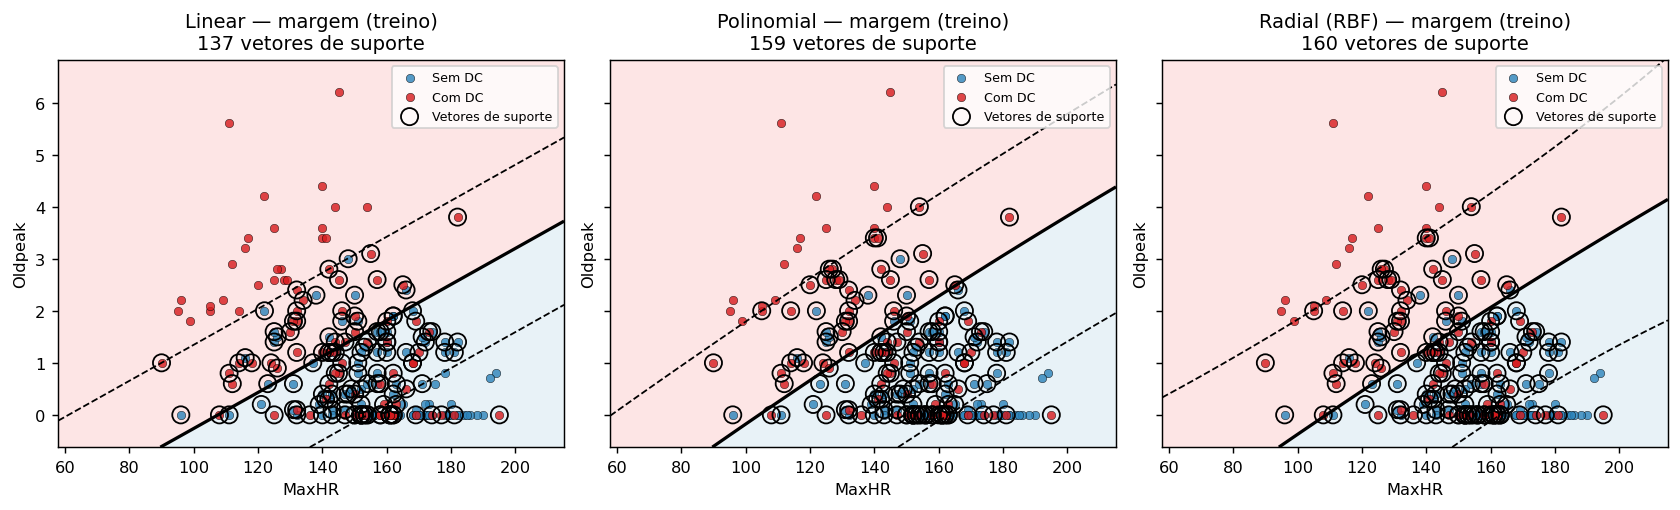

In [7]:
# margem máxima (treino)
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, (k, m) in zip(axs, models.items()):
    Z = dec(m)
    ax.contourf(GX, GY, Z, levels=[-99, 0, 99], colors=CMAP.colors, alpha=.25)
    ax.contour(GX, GY, Z, levels=[-1, 1], colors="k", linestyles="--", linewidths=1)
    ax.contour(GX, GY, Z, levels=[0], colors="k", linewidths=1.8)
    scatter(ax, Xtr, ytr_, "")
    sv = m.named_steps["sc"].inverse_transform(m.named_steps["svm"].support_vectors_)
    ax.scatter(sv[:, 0], sv[:, 1], s=90, facecolors="none", edgecolors="k", lw=1, label="Vetores de suporte")
    ax.set_title(f"{names[k]} — margem (treino)\n{len(sv)} vetores de suporte"); ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.savefig(FIG + "02_margem.png"); plt.show()

## Regiões e fronteiras de decisão (treino e teste)

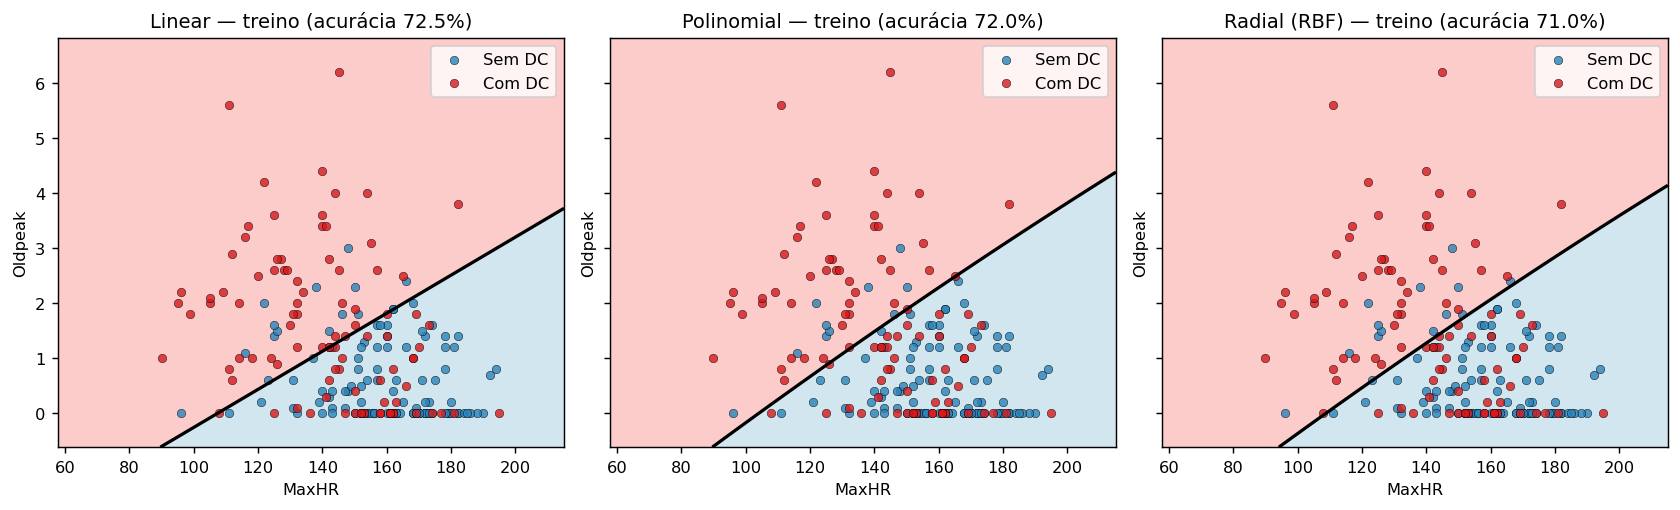

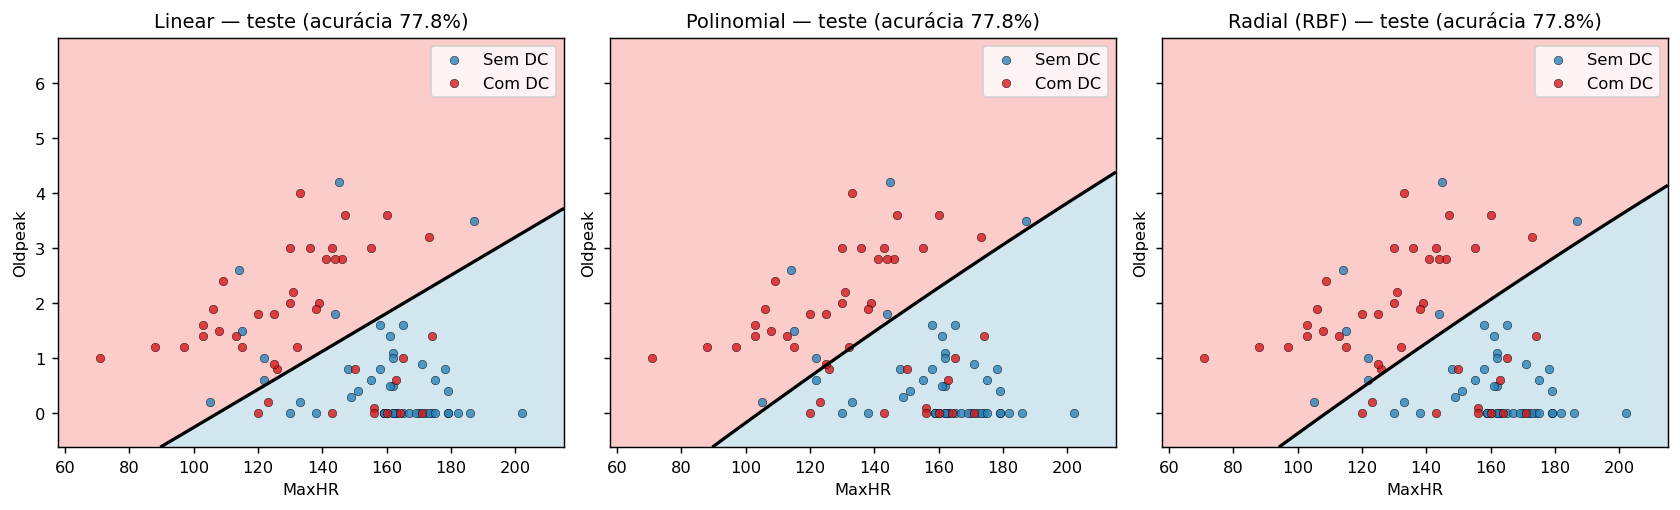

In [8]:
# regiões/fronteiras
def regions(X, y, fname, tag):
    fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
    for ax, (k, m) in zip(axs, models.items()):
        Z = dec(m)
        ax.contourf(GX, GY, Z > 0, levels=[-.5, .5, 1.5], colors=CMAP.colors, alpha=.5)
        ax.contour(GX, GY, Z, levels=[0], colors="k", linewidths=1.8)
        scatter(ax, X, y, "")
        acc = accuracy_score(y, m.predict(X))
        ax.set_title(f"{names[k]} — {tag} (acurácia {acc*100:.1f}%)")
    plt.tight_layout(); plt.savefig(FIG + fname); plt.show()
regions(Xtr, ytr_, "03_regioes_treino.png", "treino")
regions(Xte, yte_, "04_regioes_teste.png", "teste")

## 7. Incidência de DC e acurácia (teste)

In [9]:
# incidência de DC e acurácia (teste)
rows = []
for k, m in models.items():
    p = m.predict(Xte); tn, fp, fn, tp = confusion_matrix(yte_, p).ravel()
    rows.append(dict(kernel=names[k], params=best[k]["params"], cv=best[k]["cv"],
                     acc_tr=accuracy_score(ytr_, m.predict(Xtr)), acc_te=accuracy_score(yte_, p),
                     inc_pred=p.mean(), inc_real=yte_.mean(), tn=tn, fp=fp, fn=fn, tp=tp,
                     sens=tp/(tp+fn), esp=tn/(tn+fp)))
R = pd.DataFrame(rows); print(R.drop(columns="params").round(3).to_string())

         kernel     cv  acc_tr  acc_te  inc_pred  inc_real  tn  fp  fn  tp   sens    esp
0        Linear  0.715   0.725   0.778     0.422     0.467  40   8  12  30  0.714  0.833
1    Polinomial  0.719   0.720   0.778     0.400     0.467  41   7  13  29  0.690  0.854
2  Radial (RBF)  0.715   0.710   0.778     0.422     0.467  40   8  12  30  0.714  0.833


## SVM com todas as características

In [10]:
#  Modelo com todos os recursos
cat = ["ChestPain", "Thal"]; num = [c for c in X_all.columns if c not in cat]
pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
pipe = Pipeline([("pre", pre), ("svm", SVC())])
gfull = [
 {"svm__kernel": ["linear"], "svm__C": [0.01, 0.03, 0.1, 0.3, 1, 10]},
 {"svm__kernel": ["poly"], "svm__C": [0.1, 1, 10], "svm__degree": [2, 3], "svm__gamma": ["scale", 0.01, 0.1], "svm__coef0": [0, 1]},
 {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.001, 0.01, 0.1]},
]
gs = GridSearchCV(pipe, gfull, cv=cv, scoring="accuracy", n_jobs=-1).fit(Xtr_all, ytr)
pf = gs.predict(Xte_all); tn, fp, fn, tp = confusion_matrix(yte_, pf).ravel()
full = dict(params={k.replace("svm__",""): v for k, v in gs.best_params_.items()}, cv=gs.best_score_,
            acc_te=accuracy_score(yte_, pf), inc_pred=pf.mean(), tn=tn, fp=fp, fn=fn, tp=tp,
            sens=tp/(tp+fn), esp=tn/(tn+fp))
print("\nModelo completo:", full)


Modelo completo: {'params': {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}, 'cv': np.float64(0.8307781649245063), 'acc_te': 0.8333333333333334, 'inc_pred': np.float64(0.36666666666666664), 'tn': np.int64(45), 'fp': np.int64(3), 'fn': np.int64(12), 'tp': np.int64(30), 'sens': np.float64(0.7142857142857143), 'esp': np.float64(0.9375)}
